In [129]:
from langgraph.graph import StateGraph, START, END
from langchain_groq import ChatGroq
from dotenv import load_dotenv
from langgraph.types import Send
import os
from pydantic import BaseModel
from langgraph.graph.message import Annotated
from langgraph.checkpoint.memory import InMemorySaver
import operator

In [130]:
load_dotenv()

model = os.getenv('GROQ_MODEL')
api_key = os.getenv('GROQ_API_KEY')

llm = ChatGroq(model=model, api_key=api_key)

In [131]:
class Document(BaseModel):
    id: int = 0
    title: str = ""

class SummaryState(BaseModel):
    data: list[Document] = []
    summaries: Annotated[list, operator.add] = []

def route_to_summarise(state:SummaryState):
    sends = []
    for data in state.data:
        sends.append(Send("summarize", data))

    return sends

def summarize(data:Document):
    res = llm.invoke(f'summarize the title in 10 words {data.title}')

    return {'summaries':[{'id':data.id, 'summary':res.content}]}

# def collect_all(state:SummaryState):
#     print("All Summaries: ", state.summaries)
#     return {}

In [132]:
graph = StateGraph(SummaryState)

graph.add_node("summarize", summarize)
# graph.add_node("collect_all", collect_all)

graph.add_conditional_edges(START, route_to_summarise, ["summarize"])
# graph.add_edge("summarize", "collect_all")
# graph.add_edge("collect_all", END)
graph.add_edge("summarize", END)

app = graph.compile()

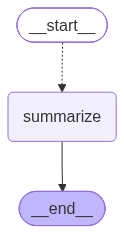

In [133]:
app

In [134]:
DOCUMENTS = [
        {'id':1, 'title':'GenAI'},
        {'id':2, 'title':'Tanstack'},
        {'id':3, 'title':'Tailwind CSS'}
    ]

In [136]:
res = app.invoke({'data':DOCUMENTS,'summaries':[]})
res['summaries']

[{'id': 1,
  'summary': 'Generative AI transforms creative processes, enabling unprecedented daily content creation.'},
 {'id': 2,
  'summary': 'TanStack: powerful, flexible UI component library for modern web applications.'},
 {'id': 3,
  'summary': 'Utility‑first framework for rapid, responsive, and customizable web design.'}]